In [1]:
import osmnx as ox
import geopandas as gpd
import matplotlib.pyplot as plt

print('ox', ox.__version__)
print('geo', gpd.__version__)

ox 2.1.1
geo 1.2.0


In [2]:
place = "Almaty, Kazakhstan"
tags = {"amenity" : "cafe"}

cafes = ox.features_from_place(place,tags)

In [3]:
print(cafes.shape) # size of dataset
print(cafes.columns.tolist())

(731, 116)
['geometry', 'amenity', 'name', 'internet_access', 'addr:housenumber', 'addr:street', 'check_date', 'name:kk', 'name:tr', 'opening_hours', 'indoor_seating', 'outdoor_seating', 'email', 'name:en', 'phone', 'website', 'cuisine', 'addr:city', 'addr:country', 'smoking', 'contact:phone', 'contact:website', 'addr:street:kk', 'addr:street:ru', 'contact:instagram', 'start_date', 'air_conditioning', 'bar', 'delivery', 'drive_through', 'highchair', 'name:ru', 'fixme', 'source', 'note', 'bic', 'brand', 'brand:wikidata', 'official_name', 'takeaway', 'addr:postcode', 'description', 'level', 'wheelchair', 'diet:vegan', 'diet:vegetarian', 'operator', 'contact:email', 'facebook', 'internet_access:fee', 'site_name', 'addr:unit', 'self_service', 'toilets', 'website:menu', 'check_date:opening_hours', 'opening_hours:signed', 'payment:cash', 'payment:credit_cards', 'payment:debit_cards', 'brand:wikipedia', 'payment:mastercard', 'payment:visa', 'contact:facebook', 'addr:floor', 'check_date:toilet

In [4]:
cafes.head()

geometry amenity             name  \
element id                                                              
node    636757283  POINT (76.94064 43.25706)    cafe  Самба-гриль-Бар   
        636764015  POINT (76.89885 43.29805)    cafe             Баян   
        636782439  POINT (76.91463 43.26782)    cafe              NaN   
        636782444  POINT (76.92903 43.26952)    cafe            Амара   
        636815207  POINT (76.90153 43.24348)    cafe           Тайфун   

                  internet_access addr:housenumber addr:street check_date  \
element id                                                                  
node    636757283             NaN              NaN         NaN        NaN   
        636764015             NaN              NaN         NaN        NaN   
        636782439             NaN              NaN         NaN        NaN   
        636782444             NaN              NaN         NaN        NaN   
        636815207             NaN              NaN         NaN        NaN   

                  name:kk name:tr opening_hours  ... building:material  \
element id                                       ...                     
node    636757283     NaN     NaN           NaN  ...               NaN   
        636764015     NaN     NaN           NaN  ...               NaN   
        636782439     NaN     NaN           NaN  ...               NaN   
        636782444     NaN     NaN           NaN  ...               NaN   
        636815207     NaN     NaN           NaN  ...               NaN   

                  roof:shape barrier int_name addr:district description:ru  \
element id                                                                   
node    636757283        NaN     NaN      NaN           NaN            NaN   
        636764015        NaN     NaN      NaN           NaN            NaN   
        636782439        NaN     NaN      NaN           NaN            NaN   
        636782444        NaN     NaN      NaN           NaN            NaN   
        636815207        NaN     NaN      NaN           NaN            NaN   

                  seasonal addr:street:en area type  
element id                                           
node    636757283      NaN            NaN  NaN  NaN  
        636764015      NaN            NaN  NaN  NaN  
        636782439      NaN            NaN  NaN  NaN  
        636782444      NaN            NaN  NaN  NaN  
        636815207      NaN            NaN  NaN  NaN  

[5 rows x 116 columns]

In [5]:
cafes.isnull().sum()

geometry              0
amenity               0
name                164
internet_access     623
addr:housenumber    514
                   ... 
description:ru      730
seasonal            730
addr:street:en      730
area                730
type                730
Length: 116, dtype: int64

In [6]:
cafes.isna().mean()

geometry            0.000000
amenity             0.000000
name                0.224350
internet_access     0.852257
addr:housenumber    0.703146
                      ...   
description:ru      0.998632
seasonal            0.998632
addr:street:en      0.998632
area                0.998632
type                0.998632
Length: 116, dtype: float64

In [7]:
cafe_top_15 = cafes.isna().mean().sort_values(ascending=True)
cafe_top_15.head(15)

geometry            0.000000
amenity             0.000000
name                0.224350
cuisine             0.621067
opening_hours       0.678523
addr:street         0.697674
addr:housenumber    0.703146
outdoor_seating     0.793434
addr:city           0.829001
building            0.835841
internet_access     0.852257
check_date          0.871409
name:en             0.875513
contact:phone       0.882353
contact:website     0.883721
dtype: float64

In [8]:
unique_geom_types = cafes.geometry.geom_type
unique_geom_types.value_counts()

Point      608
Polygon    123
Name: count, dtype: int64

In [9]:
print(cafes['name'].value_counts(dropna=False))
print(cafes['name'].nunique())

name
NaN                  164
Degirmen              35
Starbucks             21
Nedelka                8
Mixue                  8
                    ... 
Уют                    1
Park cafe              1
Aspan Terrenqour       1
Ozen Ulken Almaty      1
Umai                   1
Name: count, Length: 426, dtype: int64
425


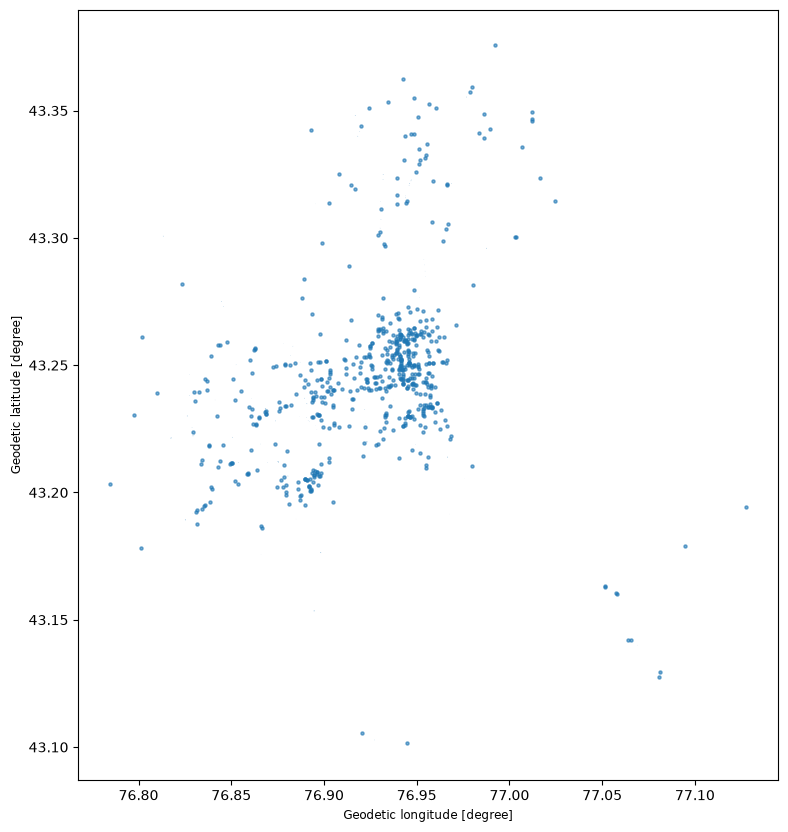

In [10]:
import matplotlib.pyplot as plt
ax = cafes.plot(figsize=(10,10), markersize=5, alpha=0.6)

In [11]:
print(cafes.crs)

epsg:4326


because we have espg:4326 that means that all longitude and latitude measures in degrees, so we need to change it into metres

In [12]:
metrics_crs = cafes.estimate_utm_crs() # подбирает подходящую метрическую систему координат для Алматы

cafes_m = cafes.to_crs(metrics_crs) # преобразует геометрию в нужную нам систему(метрическую)

print(metrics_crs)
print(cafes_m.crs)


EPSG:32643
EPSG:32643


In [13]:
print(cafes.geometry.iloc[0])
print(cafes_m.geometry.iloc[0])

POINT (76.9406391 43.2570616)
POINT (657519.169405143 4791190.10973556)


In [14]:
first_candidate = cafes_m.geometry.iloc[0] #первый кандидат(тестовая точка)

buffer_500m = first_candidate.buffer(500) #создает геометрическую област на расстоянии 500м от нашего первого кандидата


In [15]:
for i in range(5):
    print(cafes_m.geometry.iloc[i])

POINT (657519.169405143 4791190.10973556)
POINT (654023.6655503778 4795664.264842513)
POINT (655380.897970499 4792335.856279814)
POINT (656545.189976213 4792551.531595391)
POINT (654378.5874962267 4789608.968607422)


In [16]:
cafes_inside_500m = cafes_m[cafes_m.geometry.intersects(buffer_500m)]

print(f"Number of cafes within 500m: {len(cafes_inside_500m)}")

Number of cafes within 500m: 42


In [17]:
print(cafes_inside_500m.geometry.geom_type.value_counts())

Point      40
Polygon     2
Name: count, dtype: int64


In [18]:
second_candidate = cafes_m.geometry.iloc[450]
print(second_candidate)

buffer_second_500m = second_candidate.buffer(500)

cafe_second_inside_500m = cafes_m[cafes_m.geometry.intersects(buffer_second_500m)]
print(len(cafe_second_inside_500m))
print(cafe_second_inside_500m.geometry.geom_type.value_counts())

POINT (656928.7621306339 4789408.196134035)
16
Point    16
Name: count, dtype: int64


(4790390.10973556, 4791990.10973556)

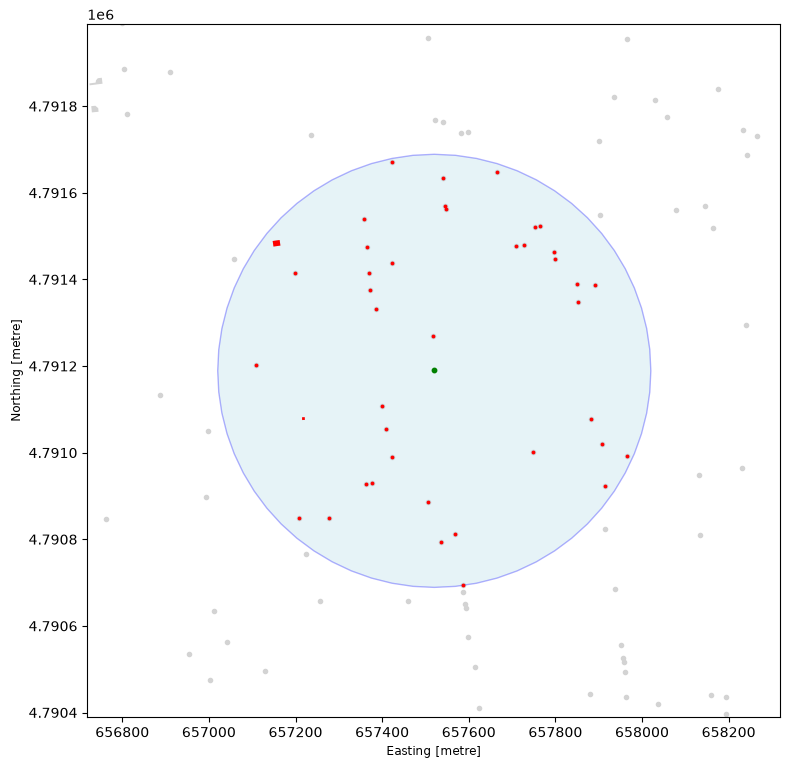

In [19]:
fig, ax = plt.subplots(figsize=(9,9)) # fig - фигура, ax = просто оси координат


cafes_m.plot(ax=ax,color='lightgray', markersize=9) # все кафе в Алмате

#радиус 500м который выбрали для теста
gpd.GeoSeries([buffer_500m], crs=cafes_m.crs).plot(
    ax = ax, color='lightblue', alpha=0.3, edgecolor='blue'
)

#наши кафе которые попали в радиус
cafes_inside_500m.plot(ax=ax, color='red', markersize=3)

#наш первый кандидат
gpd.GeoSeries([first_candidate], crs=cafes_m.crs).plot(
    ax = ax, color='green', markersize=10
)

#задаются лимиты чтобы весь Алматы не показывало

#чем больше значение мы отнимаем тем больше саму Алмату показывает

ax.set_xlim(first_candidate.x - 800, first_candidate.x + 800)
ax.set_ylim(first_candidate.y - 800, first_candidate.y + 800)



In [20]:
def count_nearby_cafes(candidate, cafes_m, radius=500):
    buffer_cafe = candidate.buffer(radius)
    return cafes_m.geometry.intersects(buffer_cafe).sum()

In [21]:
test_candidate = cafes_m.geometry.iloc[600]

for radius in [300, 500, 1000, 2000, 5000]:
    cnt = count_nearby_cafes(test_candidate, cafes_m, radius)
    print(f"Radius: {radius}m, cafes: {cnt}")

Radius: 300m, cafes: 2
Radius: 500m, cafes: 3
Radius: 1000m, cafes: 17
Radius: 2000m, cafes: 107
Radius: 5000m, cafes: 395


In [22]:
# убираем полигоны из датасета, будет работать ток с точками
cafes_points = cafes_m.copy()
cafes_points['geometry'] = cafes_points.geometry.representative_point()

In [23]:
print(cafes_points.geometry.geom_type.value_counts())

Point    731
Name: count, dtype: int64


In [24]:
for i in range(len(cafes_m)):
    some_candidate = cafes_m.geometry.iloc[i]
    if count_nearby_cafes(some_candidate, cafes_m, radius=500) != count_nearby_cafes(some_candidate, cafes_points, radius=500):
        print('diff')

# print(count_nearby_cafes(some_candidate, cafes_m, radius=500))
# print(count_nearby_cafes(some_candidate, cafes_points, radius=500))



diff
diff
diff
diff
diff
diff
diff
diff
diff
diff
diff
diff
diff
diff
diff
diff
diff
diff
diff
diff


In [25]:
differences = 0
max_diff = 0

for i in range(len(cafes_m)):
    some_candidate = cafes_points.geometry.iloc[i]

    original_dataset = count_nearby_cafes(some_candidate, cafes_m, radius=500)
    changed_dataset = count_nearby_cafes(some_candidate, cafes_points, radius=500)

    difference = abs(original_dataset - changed_dataset)

    if difference > 0:
        differences+=1
        max_diff = max(difference, max_diff)


print("Locations with differences:", differences)
print("Maximum difference:", max_diff)

Locations with differences: 31
Maximum difference: 2


In [26]:
from pathlib import Path

Path("../data/processed").mkdir(parents=True, exist_ok=True)

cafes_points.to_file(
    "../data/processed/cafes_points.gpkg",
    driver="GPKG"
)